<a href="https://colab.research.google.com/github/yeab-samuel/commit-message-generator/blob/main/notebooks/commit_message_generator.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
   print("Hello, commit messages!")


Hello, commit messages!


In [ ]:
   !pip install -q datasets

   from datasets import load_dataset

   data = load_dataset("Maxscha/commitbench", split="train", streaming=True)

   for row in data.take(2):
       print("MESSAGE:", row["message"])
       print("DIFF:", row["diff"][:500])
       print("-" * 40)

README.md:   0%|          | 0.00/5.67k [00:00<?, ?B/s]

MESSAGE: refactoring to use PhaseDiagram.pd_coords
DIFF: diff --git a/pymatgen/phasediagram/analyzer.py b/pymatgen/phasediagram/analyzer.py
index <HASH>..<HASH> 100644
--- a/pymatgen/phasediagram/analyzer.py
+++ b/pymatgen/phasediagram/analyzer.py
@@ -68,7 +68,7 @@ class PDAnalyzer(object):
         if set(comp.elements).difference(self._pd.elements):
             raise ValueError('{} has elements not in the phase diagram {}'
                              ''.format(comp, self._pd.elements))
-        c = [comp.get_atomic_fraction(e) for e in self._pd.e
----------------------------------------
MESSAGE: refactor(replset): reduce server count when destroyed
DIFF: diff --git a/lib/core/topologies/replset.js b/lib/core/topologies/replset.js
index <HASH>..<HASH> 100644
--- a/lib/core/topologies/replset.js
+++ b/lib/core/topologies/replset.js
@@ -300,15 +300,11 @@ function connectNewServers(self, servers, callback) {
 
       // Destroyed
       if (self.state === DESTROYED || self.state === U

In [ ]:
   import json

   def is_python_only(diff):
       # find the "diff --git ..." lines = one per changed file
       files = [line.split(" b/")[-1] for line in diff.split("\n") if line.startswith("diff --git")]
       return len(files) == 1 and files[0].endswith(".py")

   data = load_dataset("Maxscha/commitbench", split="train", streaming=True)
   data = data.shuffle(seed=42, buffer_size=5000)

   examples = []
   for row in data:
       if is_python_only(row["diff"]) and len(row["diff"]) < 2000:
           examples.append({"diff": row["diff"], "message": row["message"]})
       if len(examples) == 300:
           break

   dev = examples[:100]
   test = examples[100:]

   json.dump(dev, open("dev.json", "w"))
   json.dump(test, open("test.json", "w"))

   print(len(dev), len(test))
   print("Example message:", examples[0]["message"])

100 200
Example message: Fix incorrect method call on StringIO in store.


In [ ]:
   import torch
   from transformers import AutoTokenizer, AutoModelForCausalLM

   model_name = "Qwen/Qwen2.5-Coder-1.5B-Instruct"
   tokenizer = AutoTokenizer.from_pretrained(model_name)
   model = AutoModelForCausalLM.from_pretrained(model_name, torch_dtype=torch.float16).to("cuda")

   def generate_message(diff):
       prompt = ("Write a one-line git commit message for this code change. "
                 "Reply with only the message.\n\n" + diff)
       chat = [{"role": "user", "content": prompt}]
       text = tokenizer.apply_chat_template(chat, tokenize=False, add_generation_prompt=True)
       inputs = tokenizer(text, return_tensors="pt").to("cuda")
       output = model.generate(**inputs, max_new_tokens=40, do_sample=False)
       new_tokens = output[0][inputs["input_ids"].shape[1]:]
       return tokenizer.decode(new_tokens, skip_special_tokens=True).strip().split("\n")[0]

   for ex in dev[:3]:
       print("REAL:     ", ex["message"])
       print("GENERATED:", generate_message(ex["diff"]))
       print("-" * 40)

config.json:   0%|          | 0.00/660 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 3.09GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

REAL:      Fix incorrect method call on StringIO in store.
GENERATED: "Updated S3 download method to use getvalue instead of bytes."
----------------------------------------
REAL:      Renaming wrong named args to kwargs
GENERATED: Refactor fieldset initialization to use keyword arguments for clarity and flexibility.
----------------------------------------
REAL:      cleaned up code by removing commented out code
GENERATED: Fix broadcast address retrieval for non-AF_INET interfaces
----------------------------------------


In [ ]:
   !pip install -q rouge-score
   from rouge_score import rouge_scorer

   scorer = rouge_scorer.RougeScorer(["rougeL"])

   def baseline_message(diff):
       first_line = diff.split("\n")[0]      # looks like: diff --git a/x.py b/x.py
       filename = first_line.split(" b/")[-1]
       return "Update " + filename

   def average_score(examples, predict):
       scores = []
       for ex in examples:
           prediction = predict(ex["diff"])
           scores.append(scorer.score(ex["message"], prediction)["rougeL"].fmeasure)
       return sum(scores) / len(scores)

   print("Baseline:", average_score(dev, baseline_message))
   print("Model   :", average_score(dev, generate_message))

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
Baseline: 0.07253453867864286
Model   : 0.14615451572861446


In [ ]:
   def generate_with(instruction):
       def predict(diff):
           prompt = instruction + "\n\n" + diff
           chat = [{"role": "user", "content": prompt}]
           text = tokenizer.apply_chat_template(chat, tokenize=False, add_generation_prompt=True)
           inputs = tokenizer(text, return_tensors="pt").to("cuda")
           output = model.generate(**inputs, max_new_tokens=40, do_sample=False)
           new_tokens = output[0][inputs["input_ids"].shape[1]:]
           message = tokenizer.decode(new_tokens, skip_special_tokens=True).strip().split("\n")[0]
           return message.strip("\"'` ")
       return predict

   short_prompt = ("Write a git commit message for this code change: one short line, "
                   "at most 10 words, starting with a verb like Fix, Add, Remove, Rename or Update. "
                   "Describe what the change does, not what the code is about. "
                   "Reply with only the message.")

   print("Short prompt:", average_score(dev, generate_with(short_prompt)))

Short prompt: 0.13364437944413418


In [ ]:
   results = []
   for ex in test:
       base = baseline_message(ex["diff"])
       pred = generate_message(ex["diff"])
       results.append({
           "diff": ex["diff"],
           "real": ex["message"],
           "baseline": base,
           "model": pred,
           "baseline_score": scorer.score(ex["message"], base)["rougeL"].fmeasure,
           "model_score": scorer.score(ex["message"], pred)["rougeL"].fmeasure,
       })

   json.dump(results, open("results.json", "w"), indent=2)

   n = len(results)
   print("TEST baseline:", sum(r["baseline_score"] for r in results) / n)
   print("TEST model   :", sum(r["model_score"] for r in results) / n)

TEST baseline: 0.07568542840779463
TEST model   : 0.14814146455598542


In [ ]:
   from google.colab import drive
   drive.mount("/content/drive", force_remount=True)

   import os, shutil
   os.makedirs("/content/drive/MyDrive/commit_project", exist_ok=True)
   for f in ["dev.json", "test.json", "results.json"]:
       if os.path.exists(f):
           shutil.copy(f, "/content/drive/MyDrive/commit_project/" + f)
   print(os.listdir("/content/drive/MyDrive/commit_project"))

Mounted at /content/drive
['dev.json', 'test.json', 'results.json']


In [ ]:
   eval_diffs = {e["diff"] for e in dev + test}
   eval_projects = set()
   pool = []

   stream = load_dataset("Maxscha/commitbench", split="train", streaming=True)
   stream = stream.shuffle(seed=42, buffer_size=5000)

   for row in stream:
       if is_python_only(row["diff"]) and len(row["diff"]) < 2000:
           if row["diff"] in eval_diffs:
               eval_projects.add(row["project"])
           else:
               pool.append({"diff": row["diff"], "message": row["message"], "project": row["project"]})
       if len(pool) >= 4000:
           break

   train = [r for r in pool if r["project"] not in eval_projects][:3000]

   json.dump(train, open("train.json", "w"))
   shutil.copy("train.json", "/content/drive/MyDrive/commit_project/train.json")

   print("projects used by dev/test:", len(eval_projects))
   print("train examples:", len(train))
   print("overlap with test diffs:", sum(r["diff"] in eval_diffs for r in train))

projects used by dev/test: 268
train examples: 3000
overlap with test diffs: 0


In [ ]:
   !pip install -q peft
   import time
   from peft import LoraConfig, get_peft_model

   instruction = ("Write a one-line git commit message for this code change. "
                  "Reply with only the message.\n\n")

   def build(ex):
       chat = [{"role": "user", "content": instruction + ex["diff"]}]
       prompt_text = tokenizer.apply_chat_template(chat, tokenize=False, add_generation_prompt=True)
       prompt_ids = tokenizer(prompt_text, add_special_tokens=False)["input_ids"]
       answer_ids = tokenizer(ex["message"].strip() + "<|im_end|>", add_special_tokens=False)["input_ids"]
       ids = (prompt_ids + answer_ids)[:1024]
       labels = ([-100] * len(prompt_ids) + answer_ids)[:1024]
       return torch.tensor([ids]).to("cuda"), torch.tensor([labels]).to("cuda"), len(prompt_ids)

   config = LoraConfig(r=16, lora_alpha=32, lora_dropout=0.05,
                       target_modules=["q_proj", "k_proj", "v_proj", "o_proj"],
                       task_type="CAUSAL_LM")
   model = get_peft_model(model, config)
   for p in model.parameters():
       if p.requires_grad:
           p.data = p.data.float()
   model.print_trainable_parameters()

   optimizer = torch.optim.AdamW([p for p in model.parameters() if p.requires_grad], lr=2e-4)
   scaler = torch.amp.GradScaler("cuda")

   def train_on(examples, accum=8):
       model.train()
       start, total, count = time.time(), 0.0, 0
       for i, ex in enumerate(examples, 1):
           ids, labels, prompt_len = build(ex)
           if prompt_len >= 900:      # skip diffs that are too long
               continue
           with torch.autocast("cuda", dtype=torch.float16):
               loss = model(input_ids=ids, labels=labels).loss
           scaler.scale(loss / accum).backward()
           total += loss.item()
           count += 1
           if i % accum == 0:
               scaler.step(optimizer)
               scaler.update()
               optimizer.zero_grad()
           if i % 10 == 0:
               print(i, "avg loss:", round(total / count, 3), "| time:", round(time.time() - start), "s")
               total, count = 0.0, 0
       model.eval()

   train_on(train[:30])

trainable params: 4,358,144 || all params: 1,548,072,448 || trainable%: 0.2815
10 avg loss: 3.66 | time: 10 s
20 avg loss: 4.216 | time: 15 s
30 avg loss: 4.938 | time: 18 s


In [ ]:
   !pip uninstall -y torchao

Found existing installation: torchao 0.10.0
Uninstalling torchao-0.10.0:
  Successfully uninstalled torchao-0.10.0


In [ ]:
   def train_on(examples, accum=8, log_every=250):
       model.train()
       start, total, count = time.time(), 0.0, 0
       for i, ex in enumerate(examples, 1):
           ids, labels, prompt_len = build(ex)
           if prompt_len >= 900:
               continue
           with torch.autocast("cuda", dtype=torch.float16):
               loss = model(input_ids=ids, labels=labels).loss
           scaler.scale(loss / accum).backward()
           total += loss.item()
           count += 1
           if i % accum == 0:
               scaler.step(optimizer)
               scaler.update()
               optimizer.zero_grad()
           if i % log_every == 0:
               print(i, "avg loss:", round(total / count, 3), "| time:", round(time.time() - start), "s")
               total, count = 0.0, 0
       model.eval()

   save_dir = "/content/drive/MyDrive/commit_project/lora_adapter"
   for chunk_start in range(0, 3000, 1000):
       print("=== examples", chunk_start, "to", chunk_start + 1000, "===")
       train_on(train[chunk_start:chunk_start + 1000])
       model.save_pretrained(save_dir)
       print("saved to Drive")

=== examples 0 to 1000 ===
250 avg loss: 3.111 | time: 54 s
500 avg loss: 2.916 | time: 112 s
750 avg loss: 2.856 | time: 165 s
1000 avg loss: 2.966 | time: 216 s
saved to Drive
=== examples 1000 to 2000 ===
250 avg loss: 2.84 | time: 52 s
500 avg loss: 2.73 | time: 103 s
750 avg loss: 2.808 | time: 153 s
1000 avg loss: 2.891 | time: 204 s
saved to Drive
=== examples 2000 to 3000 ===
250 avg loss: 2.929 | time: 51 s
500 avg loss: 2.794 | time: 100 s
750 avg loss: 2.733 | time: 150 s
1000 avg loss: 2.802 | time: 199 s
saved to Drive


In [ ]:
   def generate_finetuned(diff):
       prompt = instruction + diff
       chat = [{"role": "user", "content": prompt}]
       text = tokenizer.apply_chat_template(chat, tokenize=False, add_generation_prompt=True)
       inputs = tokenizer(text, return_tensors="pt").to("cuda")
       with torch.no_grad(), torch.autocast("cuda", dtype=torch.float16):
           output = model.generate(**inputs, max_new_tokens=40, do_sample=False)
       new_tokens = output[0][inputs["input_ids"].shape[1]:]
       return tokenizer.decode(new_tokens, skip_special_tokens=True).strip().split("\n")[0]

   for ex in dev[:5]:
       print("REAL:      ", ex["message"])
       print("FINE-TUNED:", generate_finetuned(ex["diff"]))
       print("-" * 40)

   print("Fine-tuned dev score:", average_score(dev, generate_finetuned))

REAL:       Fix incorrect method call on StringIO in store.
FINE-TUNED: Return bytes from S3 object
----------------------------------------
REAL:       Renaming wrong named args to kwargs
FINE-TUNED: Fix typo in fieldset initializer
----------------------------------------
REAL:       cleaned up code by removing commented out code
FINE-TUNED: fix device.py to work on windows
----------------------------------------
REAL:       Remove last PYTHON-<I> workaround
FINE-TUNED: Fix bug in coordinator stats test (#<I>)
----------------------------------------
REAL:       fix bug in angle conversion between turtle coordinate system and scratch coordinate system
FINE-TUNED: Fixed bug where the turtle would not turn to the correct direction
----------------------------------------
Fine-tuned dev score: 0.21582564281005864


In [ ]:
   results = json.load(open("results.json"))

   for r in results:
       pred = generate_finetuned(r["diff"])
       r["finetuned"] = pred
       r["finetuned_score"] = scorer.score(r["real"], pred)["rougeL"].fmeasure

   json.dump(results, open("results.json", "w"), indent=2)
   shutil.copy("results.json", "/content/drive/MyDrive/commit_project/results.json")

   n = len(results)
   print("TEST baseline  :", sum(r["baseline_score"] for r in results) / n)
   print("TEST prompted  :", sum(r["model_score"] for r in results) / n)
   print("TEST fine-tuned:", sum(r["finetuned_score"] for r in results) / n)

TEST baseline  : 0.07568542840779463
TEST prompted  : 0.14814146455598542
TEST fine-tuned: 0.19268073969760266


In [ ]:
   import random

   zeros = [r for r in results if r["finetuned_score"] == 0]
   print("Outputs with score 0:", len(zeros), "out of", len(results))
   print()

   random.seed(1)
   print("===== 10 RANDOM FAILURES =====")
   for r in random.sample(zeros, min(10, len(zeros))):
       print("REAL      :", r["real"])
       print("FINE-TUNED:", r["finetuned"])
       print("DIFF START:", r["diff"][:300].replace("\n", " | "))
       print("-" * 40)

   print("===== 3 BEST =====")
   for r in sorted(results, key=lambda r: r["finetuned_score"], reverse=True)[:3]:
       print("REAL      :", r["real"])
       print("FINE-TUNED:", r["finetuned"])
       print("-" * 40)

Outputs with score 0: 51 out of 200

===== 10 RANDOM FAILURES =====
REAL      : of<I>: simplify OFPActionVendor

vendor value is available as cls_vendor.
FINE-TUNED: fix bug in ofproto_v1_0_parser
DIFF START: diff --git a/ryu/ofproto/ofproto_v1_0_parser.py b/ryu/ofproto/ofproto_v1_0_parser.py | index <HASH>..<HASH> 100644 | --- a/ryu/ofproto/ofproto_v1_0_parser.py | +++ b/ryu/ofproto/ofproto_v1_0_parser.py | @@ -459,9 +459,9 @@ class OFPActionVendor(OFPAction): |              return cls |          return _register_a
----------------------------------------
REAL      : Don't redeclare `recurrence_rule` field on `BaseEventForm`.

This was making the field required even when it was not required by the model,
and seems to be redundant, anyway.
FINE-TUNED: Removed RecurrenceRuleField from admin form
DIFF START: diff --git a/eventkit/admin_forms.py b/eventkit/admin_forms.py | index <HASH>..<HASH> 100644 | --- a/eventkit/admin_forms.py | +++ b/eventkit/admin_forms.py | @@ -5,11 +5,9 @@ Admin 

In [ ]:
   def first_line(s):
       return s.strip().split("\n")[0]

   n = len(results)

   print("Model output starts with 'fix':", sum(r["finetuned"].lower().startswith("fix") for r in results), "of", n)
   print("Real message starts with 'fix' :", sum(r["real"].lower().startswith("fix") for r in results), "of", n)
   print("Model output has 'bug' or 'typo':", sum(("bug" in r["finetuned"].lower() or "typo" in r["finetuned"].lower()) for r in results), "of", n)
   print("Real message has 'bug' or 'typo' :", sum(("bug" in r["real"].lower() or "typo" in r["real"].lower()) for r in results), "of", n)
   print("Real messages with a body (2+ lines):", sum("\n" in r["real"].strip() for r in results), "of", n)
   print()

   for key in ["baseline", "model", "finetuned"]:
       s = sum(scorer.score(first_line(r["real"]), r[key])["rougeL"].fmeasure for r in results) / n
       print("TEST vs first line only -", key, ":", round(s, 3))

Model output starts with 'fix': 111 of 200
Real message starts with 'fix' : 34 of 200
Model output has 'bug' or 'typo': 59 of 200
Real message has 'bug' or 'typo' : 11 of 200
Real messages with a body (2+ lines): 39 of 200

TEST vs first line only - baseline : 0.087
TEST vs first line only - model : 0.158
TEST vs first line only - finetuned : 0.209


In [ ]:
n = len(results)
for key in ["baseline_score", "model_score", "finetuned_score"]:
    zeros = sum(r[key] == 0 for r in results)
    print(key, "zero scores:", zeros, "of", n)

baseline_score zero scores: 124 of 200
model_score zero scores: 43 of 200
finetuned_score zero scores: 51 of 200


In [ ]:
   train_projects = {r["project"] for r in train}
   train_diffs = {r["diff"] for r in train}
   blocked = eval_projects | train_projects

   stream2 = load_dataset("Maxscha/commitbench", split="train", streaming=True)
   stream2 = stream2.shuffle(seed=7, buffer_size=5000)

   test2 = []
   for row in stream2:
       if row["project"] in blocked:
           continue
       if row["diff"] in eval_diffs or row["diff"] in train_diffs:
           continue
       if is_python_only(row["diff"]) and len(row["diff"]) < 2000:
           test2.append({"diff": row["diff"], "message": row["message"], "project": row["project"]})
       if len(test2) == 200:
           break

   json.dump(test2, open("test2.json", "w"))
   shutil.copy("test2.json", "/content/drive/MyDrive/commit_project/test2.json")

   print("test2 examples:", len(test2))
   print("distinct projects:", len({r["project"] for r in test2}))
   print("projects shared with train/dev/test:", len({r["project"] for r in test2} & blocked))
   print("diffs shared with train/dev/test:", sum(r["diff"] in eval_diffs or r["diff"] in train_diffs for r in test2))

test2 examples: 200
distinct projects: 192
projects shared with train/dev/test: 0
diffs shared with train/dev/test: 0


In [ ]:
   import random

   test2_projects = {r["project"] for r in test2}
   test2_diffs = {r["diff"] for r in test2}
   blocked2 = eval_projects | test2_projects

   stream3 = load_dataset("Maxscha/commitbench", split="train", streaming=True)
   stream3 = stream3.shuffle(seed=42, buffer_size=5000)

   pool2 = []
   for row in stream3:
       if row["project"] in blocked2:
           continue
       if row["diff"] in eval_diffs or row["diff"] in test2_diffs:
           continue
       if is_python_only(row["diff"]) and len(row["diff"]) < 2000:
           first = row["message"].strip().split("\n")[0]
           pool2.append({"diff": row["diff"], "message": first, "project": row["project"]})
       if len(pool2) >= 9000:
           break

   fix_msgs = [r for r in pool2 if r["message"].lower().startswith("fix")]
   other_msgs = [r for r in pool2 if not r["message"].lower().startswith("fix")]

   train2 = other_msgs[:4500] + fix_msgs[:1500]
   random.seed(0)
   random.shuffle(train2)

   json.dump(train2, open("train2.json", "w"))
   shutil.copy("train2.json", "/content/drive/MyDrive/commit_project/train2.json")

   print("train2 examples:", len(train2))
   print("share starting with 'fix':", round(sum(r["message"].lower().startswith("fix") for r in train2) / len(train2), 3))
   print("projects shared with dev/test/test2:", len({r["project"] for r in train2} & blocked2))
   print("diffs shared with dev/test/test2:", sum(r["diff"] in eval_diffs or r["diff"] in test2_diffs for r in train2))

train2 examples: 5833
share starting with 'fix': 0.229
projects shared with dev/test/test2: 0
diffs shared with dev/test/test2: 0


In [ ]:
   test2_results = []
   for ex in test2:
       real = ex["message"]
       base_msg = baseline_message(ex["diff"])
       with torch.no_grad(), model.disable_adapter():
           prompted_msg = generate_message(ex["diff"])
       v1_msg = generate_finetuned(ex["diff"])
       test2_results.append({
           "diff": ex["diff"], "real": real,
           "baseline": base_msg, "prompted": prompted_msg, "v1": v1_msg,
       })

   json.dump(test2_results, open("test2_results.json", "w"), indent=2)
   shutil.copy("test2_results.json", "/content/drive/MyDrive/commit_project/test2_results.json")

   m = len(test2_results)
   for key in ["baseline", "prompted", "v1"]:
       full = sum(scorer.score(r["real"], r[key])["rougeL"].fmeasure for r in test2_results) / m
       first = sum(scorer.score(first_line(r["real"]), r[key])["rougeL"].fmeasure for r in test2_results) / m
       zeros = sum(scorer.score(r["real"], r[key])["rougeL"].fmeasure == 0 for r in test2_results)
       print(key, "| full:", round(full, 3), "| first line:", round(first, 3), "| zeros:", zeros, "of", m)

baseline | full: 0.082 | first line: 0.095 | zeros: 126 of 200
prompted | full: 0.167 | first line: 0.176 | zeros: 41 of 200
v1 | full: 0.196 | first line: 0.207 | zeros: 53 of 200


In [ ]:
   !pip install -q datasets peft rouge-score
   !pip uninstall -y torchao

   from google.colab import drive
   drive.mount("/content/drive")

   import json, shutil, time, random, torch
   from transformers import AutoTokenizer, AutoModelForCausalLM
   from peft import PeftModel
   from rouge_score import rouge_scorer

   folder = "/content/drive/MyDrive/commit_project/"
   dev = json.load(open(folder + "dev.json"))
   test = json.load(open(folder + "test.json"))
   test2 = json.load(open(folder + "test2.json"))
   train = json.load(open(folder + "train.json"))
   train2 = json.load(open(folder + "train2.json"))
   results = json.load(open(folder + "results.json"))

   model_name = "Qwen/Qwen2.5-Coder-1.5B-Instruct"
   tokenizer = AutoTokenizer.from_pretrained(model_name)
   base = AutoModelForCausalLM.from_pretrained(model_name, torch_dtype=torch.float16).to("cuda")
   model = PeftModel.from_pretrained(base, folder + "lora_adapter")
   model.eval()

   instruction = ("Write a one-line git commit message for this code change. "
                  "Reply with only the message.\n\n")
   scorer = rouge_scorer.RougeScorer(["rougeL"])

   def first_line(s):
       return s.strip().split("\n")[0]

   def baseline_message(diff):
       first = diff.split("\n")[0]
       return "Update " + first.split(" b/")[-1]

   def generate_finetuned(diff):
       chat = [{"role": "user", "content": instruction + diff}]
       text = tokenizer.apply_chat_template(chat, tokenize=False, add_generation_prompt=True)
       inputs = tokenizer(text, return_tensors="pt").to("cuda")
       with torch.no_grad(), torch.autocast("cuda", dtype=torch.float16):
           output = model.generate(**inputs, max_new_tokens=40, do_sample=False)
       new_tokens = output[0][inputs["input_ids"].shape[1]:]
       return tokenizer.decode(new_tokens, skip_special_tokens=True).strip().split("\n")[0]

   generate_message = generate_finetuned   # same function; "prompted" = run it with the adapter switched off

   print("dev/test/test2/train/train2:", len(dev), len(test), len(test2), len(train), len(train2))
   print("check:", generate_finetuned(dev[0]["diff"]))

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
Found existing installation: torchao 0.10.0
Uninstalling torchao-0.10.0:
  Successfully uninstalled torchao-0.10.0
Mounted at /content/drive


config.json:   0%|          | 0.00/660 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

... (2 outputs left out)

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

dev/test/test2/train/train2: 100 200 200 3000 5833
check: Return bytes from S3 object


In [ ]:
   import gc
   from peft import LoraConfig, get_peft_model

   # free the old model, then load a fresh base model
   del model, base
   gc.collect()
   torch.cuda.empty_cache()

   base = AutoModelForCausalLM.from_pretrained(model_name, torch_dtype=torch.float16).to("cuda")

   config = LoraConfig(r=16, lora_alpha=32, lora_dropout=0.05,
                       target_modules=["q_proj", "k_proj", "v_proj", "o_proj"],
                       task_type="CAUSAL_LM")
   model = get_peft_model(base, config)
   for p in model.parameters():
       if p.requires_grad:
           p.data = p.data.float()
   model.print_trainable_parameters()

   def build(ex):
       chat = [{"role": "user", "content": instruction + ex["diff"]}]
       prompt_text = tokenizer.apply_chat_template(chat, tokenize=False, add_generation_prompt=True)
       prompt_ids = tokenizer(prompt_text, add_special_tokens=False)["input_ids"]
       answer_ids = tokenizer(ex["message"].strip() + "<|im_end|>", add_special_tokens=False)["input_ids"]
       ids = (prompt_ids + answer_ids)[:1024]
       labels = ([-100] * len(prompt_ids) + answer_ids)[:1024]
       return torch.tensor([ids]).to("cuda"), torch.tensor([labels]).to("cuda"), len(prompt_ids)

   optimizer = torch.optim.AdamW([p for p in model.parameters() if p.requires_grad], lr=2e-4)
   scaler = torch.amp.GradScaler("cuda")

   def train_on(examples, accum=8, log_every=250):
       model.train()
       start, total, count = time.time(), 0.0, 0
       for i, ex in enumerate(examples, 1):
           ids, labels, prompt_len = build(ex)
           if prompt_len >= 900:
               continue
           with torch.autocast("cuda", dtype=torch.float16):
               loss = model(input_ids=ids, labels=labels).loss
           scaler.scale(loss / accum).backward()
           total += loss.item()
           count += 1
           if i % accum == 0:
               scaler.step(optimizer)
               scaler.update()
               optimizer.zero_grad()
           if i % log_every == 0:
               print(i, "avg loss:", round(total / count, 3), "| time:", round(time.time() - start), "s")
               total, count = 0.0, 0
       model.eval()

   save_dir = folder + "lora_adapter_v2"
   for chunk_start in range(0, len(train2), 1000):
       print("=== examples", chunk_start, "to", min(chunk_start + 1000, len(train2)), "===")
       train_on(train2[chunk_start:chunk_start + 1000])
       model.save_pretrained(save_dir)
       print("saved to Drive")

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

trainable params: 4,358,144 || all params: 1,548,072,448 || trainable%: 0.2815
=== examples 0 to 1000 ===
250 avg loss: 3.26 | time: 53 s
500 avg loss: 2.836 | time: 105 s
750 avg loss: 2.894 | time: 155 s
1000 avg loss: 2.857 | time: 206 s
saved to Drive
=== examples 1000 to 2000 ===
250 avg loss: 2.893 | time: 51 s
500 avg loss: 2.977 | time: 101 s
750 avg loss: 2.856 | time: 152 s
1000 avg loss: 2.768 | time: 202 s
saved to Drive
=== examples 2000 to 3000 ===
250 avg loss: 2.848 | time: 50 s
500 avg loss: 2.841 | time: 100 s
750 avg loss: 2.89 | time: 150 s
1000 avg loss: 2.711 | time: 200 s
saved to Drive
=== examples 3000 to 4000 ===
250 avg loss: 2.839 | time: 50 s
500 avg loss: 2.831 | time: 100 s
750 avg loss: 2.655 | time: 150 s
1000 avg loss: 2.719 | time: 201 s
saved to Drive
=== examples 4000 to 5000 ===
250 avg loss: 2.734 | time: 50 s
500 avg loss: 2.727 | time: 100 s
750 avg loss: 2.789 | time: 150 s
1000 avg loss: 2.672 | time: 200 s
saved to Drive
=== examples 5000 to 

In [ ]:
   dev_outputs = [generate_finetuned(ex["diff"]) for ex in dev]
   n = len(dev)

   full = sum(scorer.score(ex["message"], out)["rougeL"].fmeasure for ex, out in zip(dev, dev_outputs)) / n
   first = sum(scorer.score(first_line(ex["message"]), out)["rougeL"].fmeasure for ex, out in zip(dev, dev_outputs)) / n
   zeros = sum(scorer.score(ex["message"], out)["rougeL"].fmeasure == 0 for ex, out in zip(dev, dev_outputs))
   fix_count = sum(out.lower().startswith("fix") for out in dev_outputs)

   print("v2 dev | full:", round(full, 3), "| first line:", round(first, 3), "| zeros:", zeros, "of", n)
   print("v2 outputs starting with 'fix':", fix_count, "of", n)
   print()
   for ex, out in list(zip(dev, dev_outputs))[:5]:
       print("REAL:", ex["message"].strip().split("\n")[0])
       print("V2  :", out)
       print("-" * 40)

v2 dev | full: 0.193 | first line: 0.213 | zeros: 23 of 100
v2 outputs starting with 'fix': 59 of 100

REAL: Fix incorrect method call on StringIO in store.
V2  : Fix bug in s3 store
----------------------------------------
REAL: Renaming wrong named args to kwargs
V2  : Fixing issue #<I>
----------------------------------------
REAL: cleaned up code by removing commented out code
V2  : fix device.py to work on windows
----------------------------------------
REAL: Remove last PYTHON-<I> workaround
V2  : Fixing python3 compatibility issue
----------------------------------------
REAL: fix bug in angle conversion between turtle coordinate system and scratch coordinate system
V2  : Fixed some issues with the wcb script
----------------------------------------


In [ ]:
   test2_results = json.load(open(folder + "test2_results.json"))
   for r in test2_results:
       r["v2"] = generate_finetuned(r["diff"])

   json.dump(test2_results, open("test2_results.json", "w"), indent=2)
   shutil.copy("test2_results.json", folder + "test2_results.json")

   m = len(test2_results)
   def sc(real, pred):
       return scorer.score(real, pred)["rougeL"].fmeasure

   for key in ["baseline", "prompted", "v1", "v2"]:
       full = sum(sc(r["real"], r[key]) for r in test2_results) / m
       first = sum(sc(first_line(r["real"]), r[key]) for r in test2_results) / m
       zeros = sum(sc(r["real"], r[key]) == 0 for r in test2_results)
       fixes = sum(r[key].lower().startswith("fix") for r in test2_results)
       print(key, "| full:", round(full, 3), "| first line:", round(first, 3), "| zeros:", zeros, "| starts with fix:", fixes, "of", m)

   v2_wins = sum(sc(r["real"], r["v2"]) > sc(r["real"], r["v1"]) for r in test2_results)
   v1_wins = sum(sc(r["real"], r["v1"]) > sc(r["real"], r["v2"]) for r in test2_results)
   print("v2 better on", v2_wins, "| v1 better on", v1_wins, "| tied", m - v2_wins - v1_wins)

baseline | full: 0.082 | first line: 0.095 | zeros: 126 | starts with fix: 0 of 200
prompted | full: 0.167 | first line: 0.176 | zeros: 41 | starts with fix: 7 of 200
v1 | full: 0.196 | first line: 0.207 | zeros: 53 | starts with fix: 103 of 200
v2 | full: 0.193 | first line: 0.203 | zeros: 51 | starts with fix: 119 of 200
v2 better on 60 | v1 better on 78 | tied 62


['test_set', 'method', 'rougeL_full', 'rougeL_first_line', 'zero_scores', 'n']
['test1', 'baseline', 0.076, 0.087, 124, 200]
['test1', 'prompted', 0.148, 0.158, 43, 200]
['test1', 'finetuned_v1', 0.193, 0.209, 51, 200]
['test2', 'baseline', 0.082, 0.095, 126, 200]
['test2', 'prompted', 0.167, 0.176, 41, 200]
['test2', 'finetuned_v1', 0.196, 0.207, 53, 200]
['test2', 'finetuned_v2', 0.193, 0.203, 51, 200]


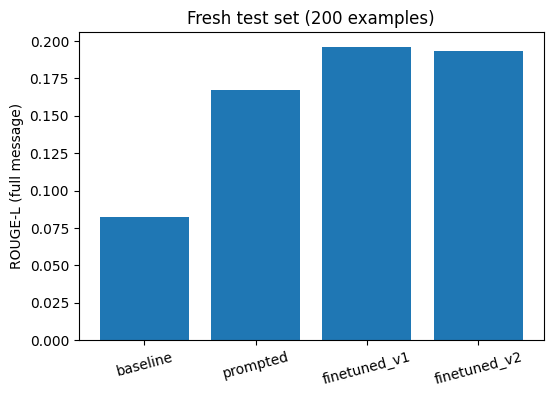

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
   import csv, os, shutil
   import matplotlib.pyplot as plt
   from google.colab import files

   out = "/content/repo_files"
   shutil.rmtree(out, ignore_errors=True)
   for sub in ["data", "results", "adapter_v1"]:
       os.makedirs(out + "/" + sub)

   # evaluation sets, raw results, and the v1 adapter
   for name in ["dev.json", "test.json", "test2.json"]:
       shutil.copy(folder + name, out + "/data/" + name)
   shutil.copy(folder + "results.json", out + "/results/test1_results.json")
   shutil.copy(folder + "test2_results.json", out + "/results/test2_results.json")
   for name in ["adapter_model.safetensors", "adapter_config.json"]:
       shutil.copy(folder + "lora_adapter/" + name, out + "/adapter_v1/" + name)

   # score table
   def sc(real, pred):
       return scorer.score(real, pred)["rougeL"].fmeasure

   t1 = json.load(open(folder + "results.json"))
   t2 = json.load(open(folder + "test2_results.json"))
   rows = [["test_set", "method", "rougeL_full", "rougeL_first_line", "zero_scores", "n"]]

   def summarize(data, name, mapping):
       n = len(data)
       for label, key in mapping:
           full = sum(sc(r["real"], r[key]) for r in data) / n
           first = sum(sc(first_line(r["real"]), r[key]) for r in data) / n
           zeros = sum(sc(r["real"], r[key]) == 0 for r in data)
           rows.append([name, label, round(full, 3), round(first, 3), zeros, n])

   summarize(t1, "test1", [("baseline", "baseline"), ("prompted", "model"), ("finetuned_v1", "finetuned")])
   summarize(t2, "test2", [("baseline", "baseline"), ("prompted", "prompted"), ("finetuned_v1", "v1"), ("finetuned_v2", "v2")])

   with open(out + "/results/summary.csv", "w", newline="") as f:
       csv.writer(f).writerows(rows)
   for row in rows:
       print(row)

   # chart
   labels = [r[1] for r in rows if r[0] == "test2"]
   vals = [r[2] for r in rows if r[0] == "test2"]
   plt.figure(figsize=(6, 4))
   plt.bar(labels, vals)
   plt.ylabel("ROUGE-L (full message)")
   plt.title("Fresh test set (200 examples)")
   plt.xticks(rotation=15)
   plt.savefig(out + "/results/test2_scores.png", dpi=150, bbox_inches="tight")
   plt.show()

   shutil.make_archive("/content/repo_files", "zip", out)
   files.download("/content/repo_files.zip")

In [ ]:
   t1 = json.load(open(folder + "results.json"))
   t2 = json.load(open(folder + "test2_results.json"))

   def sc(real, pred):
       return scorer.score(real, pred)["rougeL"].fmeasure

   for const in ["Fix bug", "Fix bug in the code", "Update", "Fix typo"]:
       s1 = sum(sc(r["real"], const) for r in t1) / len(t1)
       s2 = sum(sc(r["real"], const) for r in t2) / len(t2)
       print(const, "| test1:", round(s1, 3), "| test2:", round(s2, 3))

Fix bug | test1: 0.034 | test2: 0.032
Fix bug in the code | test1: 0.063 | test2: 0.071
Update | test1: 0.008 | test2: 0.008
Fix typo | test1: 0.029 | test2: 0.027


In [ ]:
   random.seed(123)
   sample = random.sample(t2, 30)
   json.dump(sample, open(folder + "manual_sample.json", "w"), indent=2)

   def show(start, end):
       for i in range(start, end):
           r = sample[i]
           print(f"#{i+1}")
           print("MODEL MESSAGE:", r["v1"])
           print("REAL MESSAGE :", first_line(r["real"]))
           print("DIFF:")
           print(r["diff"][:1000])
           print("=" * 60)

   show(0, 10)

#1
MODEL MESSAGE: Update pytest requirement to <I>
REAL MESSAGE : pin pytest version =>3,<4
DIFF:
diff --git a/setup.py b/setup.py
index <HASH>..<HASH> 100644
--- a/setup.py
+++ b/setup.py
@@ -51,7 +51,9 @@ setup(
         'GitPython==1.0.1',
         'MapGitConfig==1.1'
     ],
-    tests_require=['pytest'],
+    tests_require=[
+        'pytest>=3,<4'
+    ],
     # package_data={},
     entry_points={
         'console_scripts': [
#2
MODEL MESSAGE: Fix bug in GafReader.__init__
REAL MESSAGE : allow for instantiating gafobj once and reading many gaf files.
DIFF:
diff --git a/goatools/gaf_reader.py b/goatools/gaf_reader.py
index <HASH>..<HASH> 100755
--- a/goatools/gaf_reader.py
+++ b/goatools/gaf_reader.py
@@ -56,10 +56,10 @@ class GafReader(object):
     # Expected values for a Qualifier
     exp_qualifiers = set(['NOT', 'contributes_to', 'colocalizes_with'])
 
-    def __init__(self, filename, log=sys.stdout):
+    def __init__(self, filename=None, log=sys.stdout):
         self.fi

In [ ]:
   show(10, 20)


#11
MODEL MESSAGE: Added methods to get image urls
REAL MESSAGE : Added methods for pull the image urls by page, with 1 being the default
DIFF:
diff --git a/documentcloud.py b/documentcloud.py
index <HASH>..<HASH> 100644
--- a/documentcloud.py
+++ b/documentcloud.py
@@ -63,6 +63,24 @@ class Document(BaseAPIObject):
         response = urllib2.urlopen(req)
         return response.read()
     full_text = property(get_full_text)
+    
+    def get_small_image_url(self, page=1):
+        template = self.resources.page.get('image')
+        url = template.replace("{page}", str(page)).replace("{size}", "small")
+        return url
+    small_image_url = property(get_small_image_url)
+    
+    def get_thumbnail_image_url(self, page=1):
+        template = self.resources.page.get('image')
+        url = template.replace("{page}", str(page)).replace("{size}", "thumbnail")
+        return url
+    small_thumbnail_url = property(get_small_thumbnail_url)
+    
+    def get_large_image_url(self, 

In [ ]:
   from google.colab import drive
   drive.mount("/content/drive")

   import json
   folder = "/content/drive/MyDrive/commit_project/"
   sample = json.load(open(folder + "manual_sample.json"))

   def first_line(s):
       return s.strip().split("\n")[0]

   def show(start, end, n_chars=800):
       for i in range(start, end):
           r = sample[i]
           print(f"#{i+1}")
           print("MODEL MESSAGE:", r["v1"])
           print("REAL MESSAGE :", first_line(r["real"]))
           print("DIFF:")
           print(r["diff"][:n_chars])
           print("=" * 60)

   show(10, 14)

Mounted at /content/drive
#11
MODEL MESSAGE: Added methods to get image urls
REAL MESSAGE : Added methods for pull the image urls by page, with 1 being the default
DIFF:
diff --git a/documentcloud.py b/documentcloud.py
index <HASH>..<HASH> 100644
--- a/documentcloud.py
+++ b/documentcloud.py
@@ -63,6 +63,24 @@ class Document(BaseAPIObject):
         response = urllib2.urlopen(req)
         return response.read()
     full_text = property(get_full_text)
+    
+    def get_small_image_url(self, page=1):
+        template = self.resources.page.get('image')
+        url = template.replace("{page}", str(page)).replace("{size}", "small")
+        return url
+    small_image_url = property(get_small_image_url)
+    
+    def get_thumbnail_image_url(self, page=1):
+        template = self.resources.page.get('image')
+        url = template.replace("{page}", str(page)).replace("{size}", "thumbnail")
+        return url
+    small_thumbnail_url = property(get_small_
#12
MODEL MESSAGE: Fixed bug 

In [ ]:
   show(14, 18)

#15
MODEL MESSAGE: fix: fix bug in fetching emails from imap server
REAL MESSAGE : fixing error where str where expected but bytes are given
DIFF:
diff --git a/ip_assembler/tasks.py b/ip_assembler/tasks.py
index <HASH>..<HASH> 100644
--- a/ip_assembler/tasks.py
+++ b/ip_assembler/tasks.py
@@ -200,14 +200,14 @@ class IPEMailChecker(PeriodicTask):
                 # iterate the mail indices and fetch the mails
                 ips_created = 0
                 for mail_index in mail_indices[0].split():
-                    logger.info('fetching mail %(mail_index)s...' % {'mail_index': mail_index})
+                    logger.info('fetching mail %(mail_index)s...' % {'mail_index': int(mail_index)})
                     # mail data is a list with a tuple
                     sub_result, mail_data = box.fetch(mail_index, '(BODY[TEXT])')
                     if sub_result == 'OK':
 
                         # fetch the ips
                 
#16
MODEL MESSAGE: fix bug in simpleuri.py
REAL MESS

In [ ]:
   show(20, 24)

#21
MODEL MESSAGE: Added some comments about the setup instructions
REAL MESSAGE : Touch up stackato setup_instructions, actually print them, switch main
DIFF:
diff --git a/django_deployer/providers.py b/django_deployer/providers.py
index <HASH>..<HASH> 100644
--- a/django_deployer/providers.py
+++ b/django_deployer/providers.py
@@ -21,13 +21,17 @@ class PaaSProvider(object):
     setup_instructions = ""
     PYVERSIONS = {}
 
-    def init(self, site):
-        self._create_configs(site)
+    @classmethod
+    def init(cls, site):
+        cls._create_configs(site)
+        print self.setup_instructions
 
-    def deploy(self):
+    @classmethod
+    def deploy(cls):
         raise NotImplementedError()
 
-    def delete(self):
+    @classmethod
+    def delete(cls):
         raise NotImplementedError()
 
 
@@ -79,14 +83,15 @@ Just a few more steps before you're ready to deploy your app!
    the Stackato client, and then add the executable somew
#22
MODEL MESSAGE: Fix bug in generate-

In [ ]:
   show(24, 28)

#25
MODEL MESSAGE: Fix bug where sharing was not working
REAL MESSAGE : Changes for ambassadors lab class.
DIFF:
diff --git a/pods/lab.py b/pods/lab.py
index <HASH>..<HASH> 100644
--- a/pods/lab.py
+++ b/pods/lab.py
@@ -176,7 +176,7 @@ if gdata_available:
                 sheet = self._get_sheet(user)
                 for share in sheet.share_list():
                     if user in share:
-                        sheet.share_modify([user], share_type, send_notifications)
+                        sheet.share_modify(user, share_type, send_notifications=False)
                         return
                 sheet.share([user], share_type, send_notifications)
#26
MODEL MESSAGE: Fix bug where headers were not being saved when using live resources
REAL MESSAGE : Fix TypeError: None is not iterable
DIFF:
diff --git a/rc_django/cache_implementation/__init__.py b/rc_django/cache_implementation/__init__.py
index <HASH>..<HASH> 100644
--- a/rc_django/cache_implementation/__init__.py
+++ b/rc_dja

In [ ]:
   show(28, 30)

#29
MODEL MESSAGE: Fix tests to work in development mode
REAL MESSAGE : Add unit test for local resouces in dev
DIFF:
diff --git a/test_flask_avatars.py b/test_flask_avatars.py
index <HASH>..<HASH> 100644
--- a/test_flask_avatars.py
+++ b/test_flask_avatars.py
@@ -107,6 +107,16 @@ class AvatarsTestCase(unittest.TestCase):
         self.assertIn('/avatars/static/jcrop/js/Jcrop.min.js', rv)
         self.assertNotIn('<script src="https://cdn.jsdelivr.net/gh/tapmodo', rv)
 
+    def test_local_resources_when_development(self):
+        current_app.config['ENV'] = 'development'
+        rv = self.avatars.jcrop_css()
+        self.assertIn('/avatars/static/jcrop/css/Jcrop.min.css', rv)
+        self.assertNotIn('<link rel="stylesheet" href="https://cdn.jsdelivr.net/gh/tapmodo', rv)
+
+        rv = self.avatars.jcrop_js()
+        self.assertIn('/avatars/static/jcrop/js/Jcrop.min.js', rv)
+        self.assertNo
#30
MODEL MESSAGE: Removed unused num_classes route
REAL MESSAGE : Dynamically co

In [ ]:
   import csv, json
   from google.colab import drive, files
   drive.mount("/content/drive")
   folder = "/content/drive/MyDrive/commit_project/"
   sample = json.load(open(folder + "manual_sample.json"))

   labels = "O O G G G G G W O W G O G O O O O G O O W O O G O O O G O O".split()
   assert len(labels) == 30

   with open("manual_ratings.csv", "w", newline="") as f:
       w = csv.writer(f)
       w.writerow(["id", "label", "model_message", "real_message_first_line"])
       for i, (r, lab) in enumerate(zip(sample, labels), 1):
           w.writerow([i, lab, r["v1"], r["real"].strip().split("\n")[0]])

   print("G:", labels.count("G"), "| O:", labels.count("O"), "| W:", labels.count("W"))
   shutil_path = folder + "manual_ratings.csv"
   import shutil
   shutil.copy("manual_ratings.csv", shutil_path)
   files.download("manual_ratings.csv")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
G: 10 | O: 17 | W: 3


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>